# Heart Disease Prediction

**Goal:** predict whether a patient has heart disease (`HeartDisease = 1`) from 11 clinical attributes.

**Workflow**
1. Exploratory Data Analysis (EDA) – distributions, correlations, outliers and key features
2. Data preprocessing & feature engineering
3. End-to-end scikit-learn pipeline (feature engineering → preprocessing → feature selection → model)
4. Hyperparameter tuning with `GridSearchCV`
5. Comparison of **Logistic Regression, KNN and SVM** using ROC-AUC and PR-AUC

**Dataset:** 918 patients, 11 features + target (`data/heart.csv`).

## 1. Imports & settings

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, pointbiserialr

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay,
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

## 2. Load the data

In [2]:
df = pd.read_csv("data/heart.csv")
print(df.shape)
df.head()

(918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## 3. Data overview

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


In [4]:
print("Missing values :", df.isnull().sum().sum())
print("Duplicate rows :", df.duplicated().sum())
df.describe().T

Missing values : 0
Duplicate rows : 0


,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.511,9.433,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.397,18.514,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.800,109.384,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233,0.423,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809,25.460,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887,1.067,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553,0.497,0.0,0.00,1.0,1.0,1.0


In [5]:
TARGET = "HeartDisease"
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()
numerical_cols = [c for c in df.select_dtypes(include="number").columns if c not in [TARGET, "FastingBS"]]
binary_cols = ["FastingBS"]

print("Categorical:", categorical_cols)
print("Numerical  :", numerical_cols)
print("Binary     :", binary_cols)

Categorical: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Numerical  : ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
Binary     : ['FastingBS']


### 3.1 Target distribution

              count      %
HeartDisease              
1               508  55.34
0               410  44.66


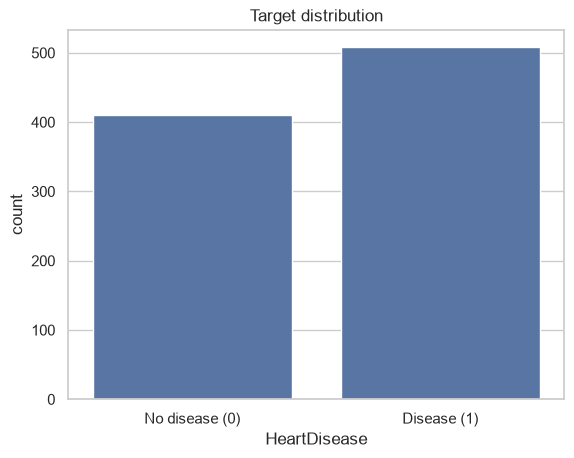

In [6]:
counts = df[TARGET].value_counts()
print(pd.concat([counts, df[TARGET].value_counts(normalize=True).mul(100).round(2)], axis=1, keys=["count", "%"]))

ax = sns.countplot(data=df, x=TARGET)
ax.set_xticklabels(["No disease (0)", "Disease (1)"])
ax.set_title("Target distribution")
plt.show()

The classes are reasonably balanced (≈55% / 45%), so no resampling is needed. A **stratified** split will keep this ratio in train and test.

## 4. Univariate analysis – distributions

### 4.1 Numerical features

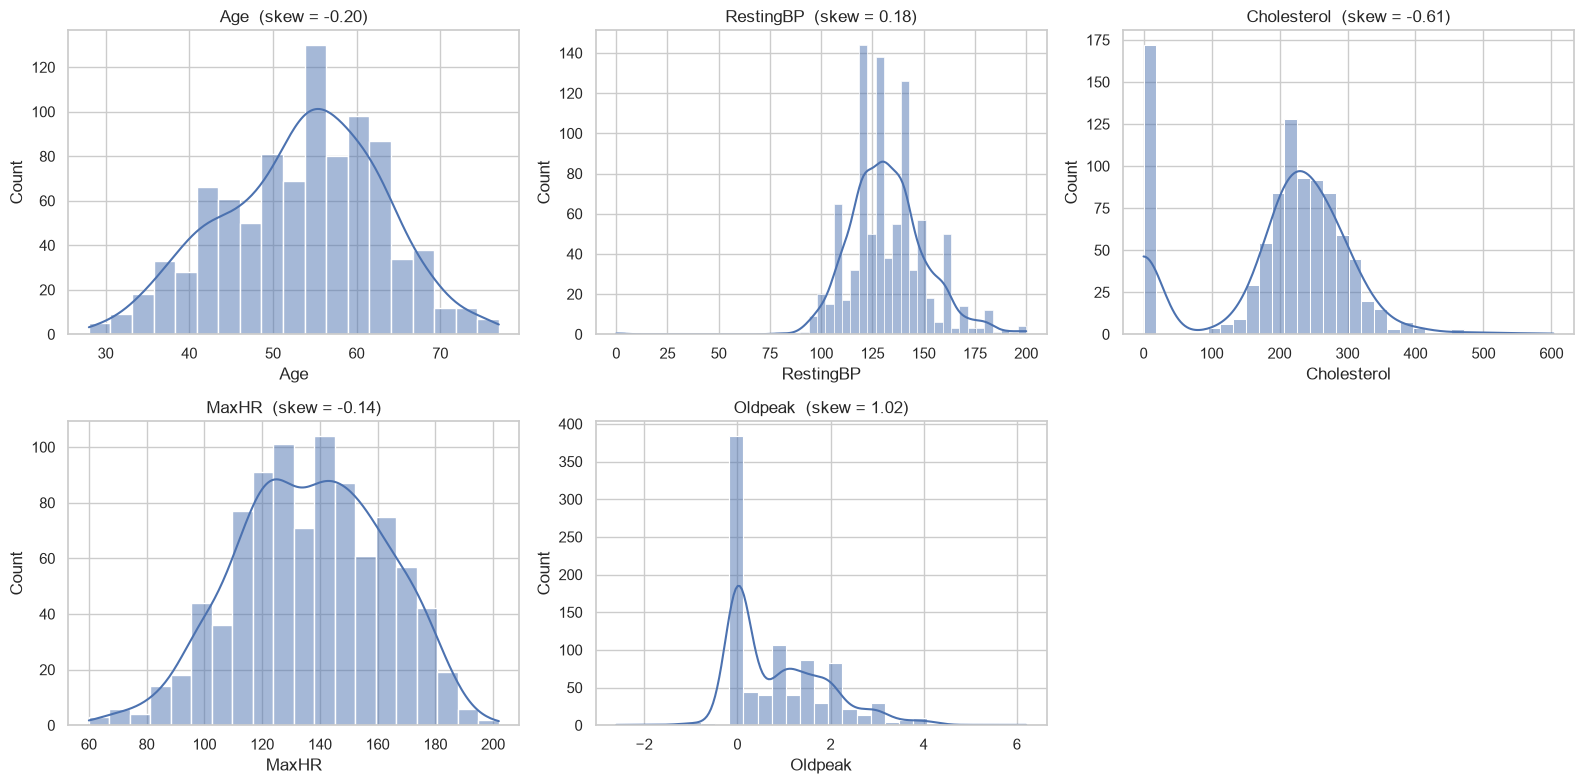

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, numerical_cols):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f"{col}  (skew = {df[col].skew():.2f})")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

- `Age` and `MaxHR` are roughly normal.
- `Cholesterol` has a large spike at **0**, which is physiologically impossible → these are missing values encoded as 0.
- `RestingBP` has a value of 0 (also impossible).
- `Oldpeak` is right-skewed with many zeros and a few negative values.

### 4.2 Categorical features

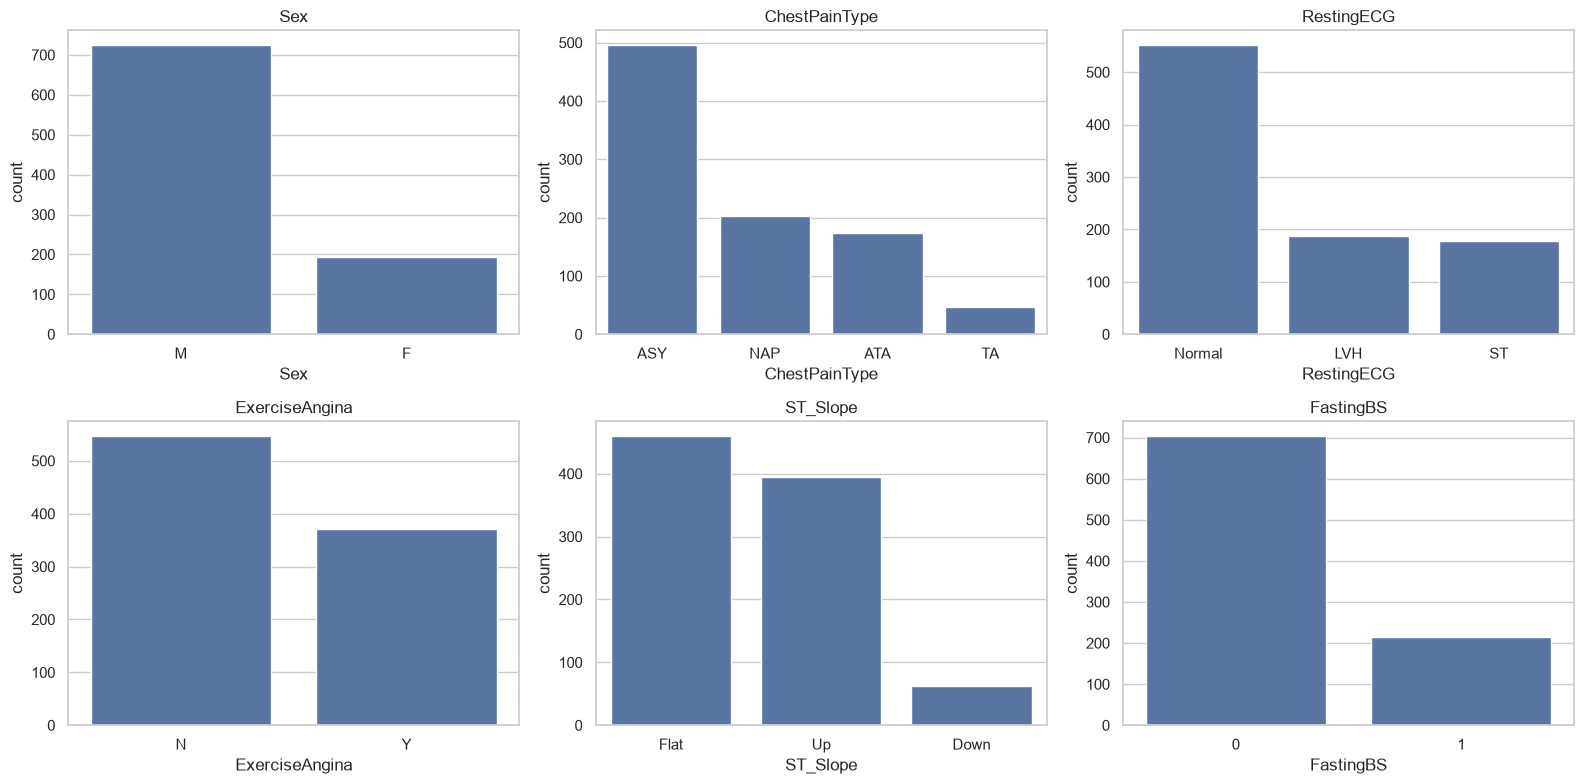

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, categorical_cols + binary_cols):
    sns.countplot(data=df, x=col, ax=ax, order=df[col].value_counts().index)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 5. Bivariate analysis – features vs target

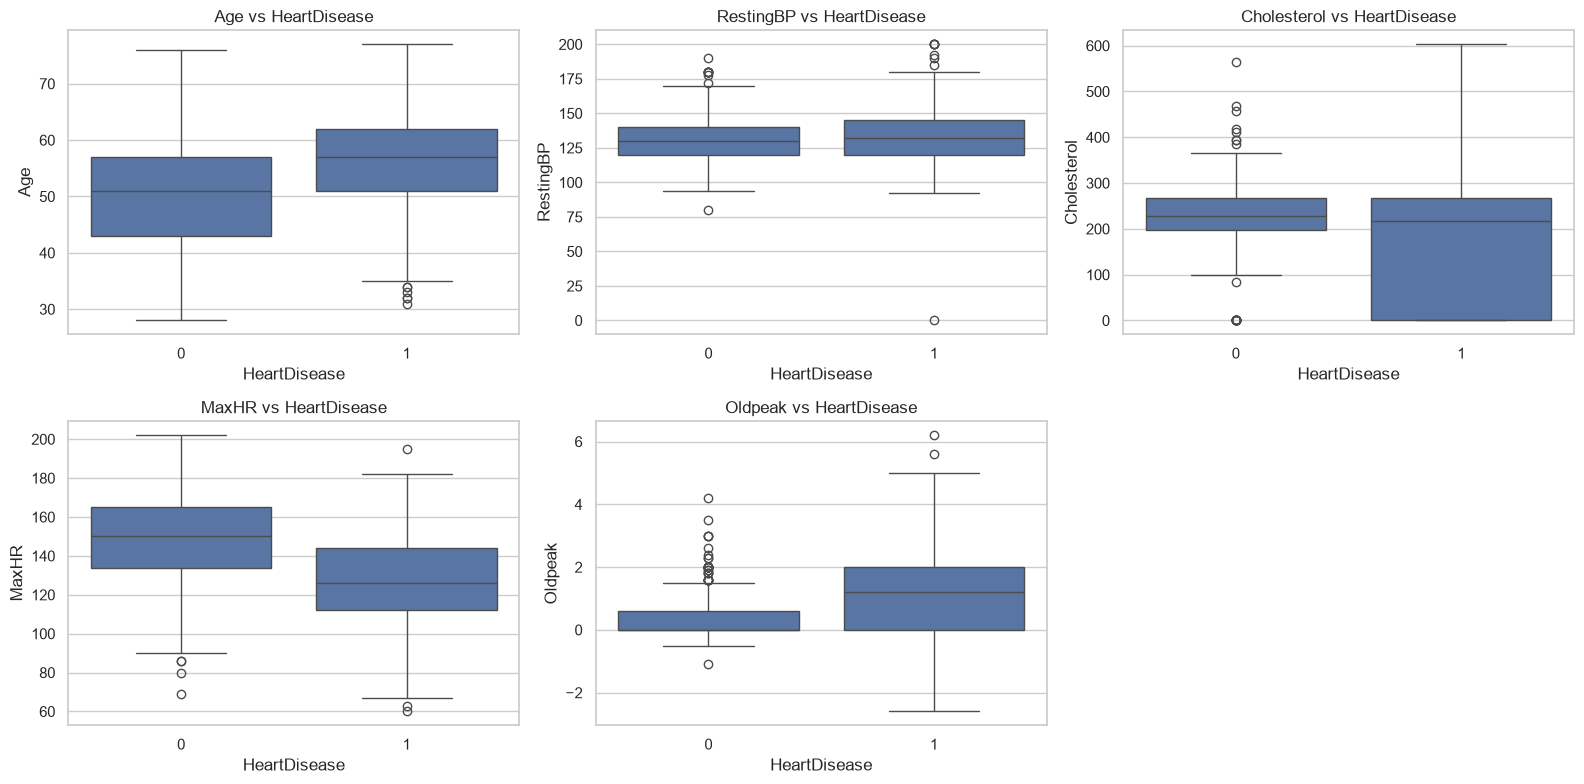

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, numerical_cols):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax)
    ax.set_title(f"{col} vs HeartDisease")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

In [10]:
df.groupby(TARGET)[numerical_cols].median().T

HeartDisease,0,1
Age,51.0,57.0
RestingBP,130.0,132.0
Cholesterol,227.0,217.0
MaxHR,150.0,126.0
Oldpeak,0.0,1.2


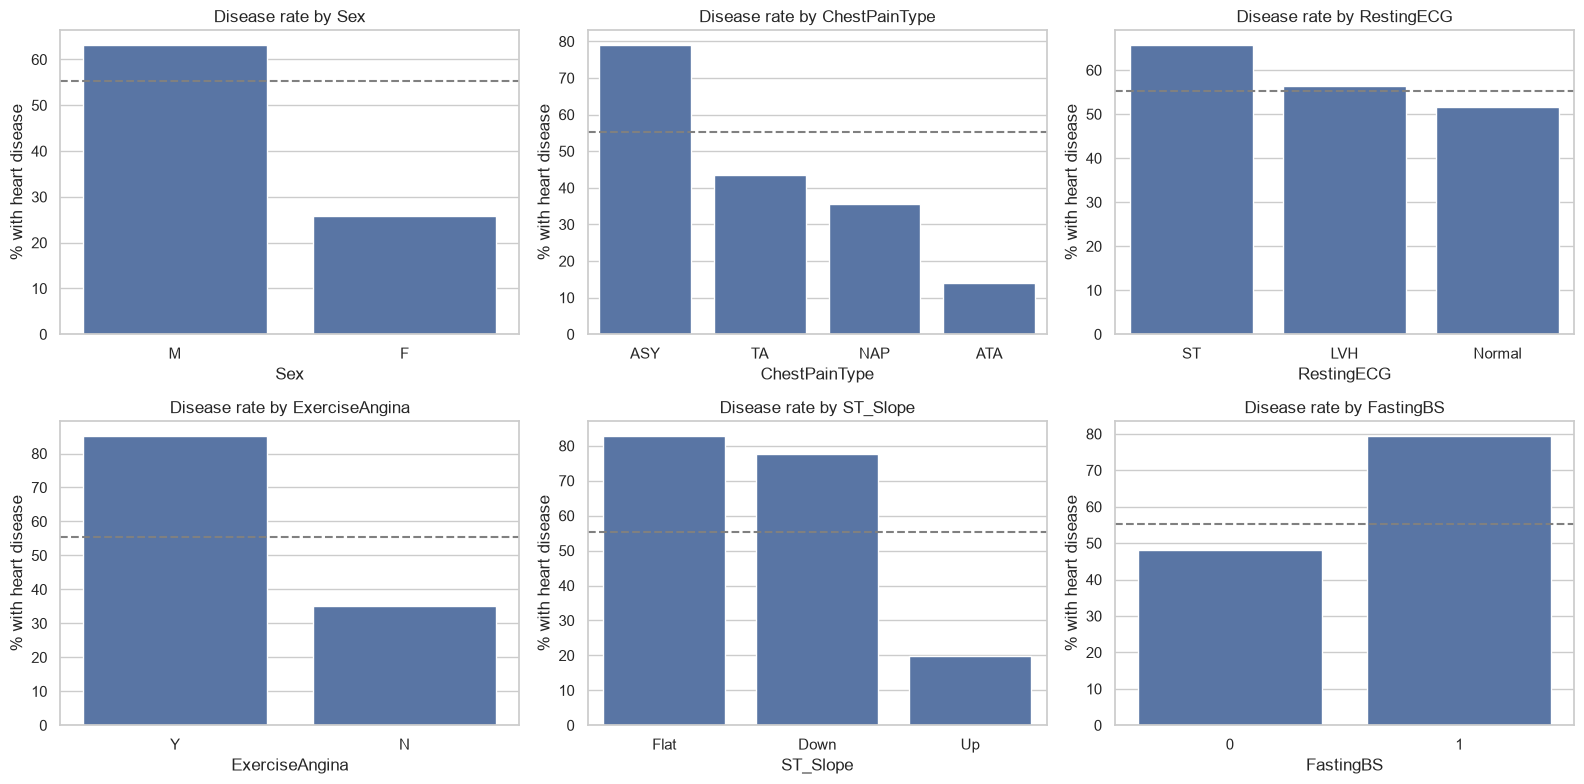

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, categorical_cols + binary_cols):
    rate = df.groupby(col)[TARGET].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    ax.set_ylabel("% with heart disease")
    ax.set_title(f"Disease rate by {col}")
    ax.axhline(df[TARGET].mean() * 100, ls="--", c="grey")
plt.tight_layout()
plt.show()

In [12]:
for col in categorical_cols + binary_cols:
    print(f"\n{'=' * 40}\n{col}\n{'=' * 40}")
    print((pd.crosstab(df[col], df[TARGET], normalize="index") * 100).round(1))


Sex
HeartDisease     0     1
Sex                     
F             74.1  25.9
M             36.8  63.2

ChestPainType
HeartDisease      0     1
ChestPainType            
ASY            21.0  79.0
ATA            86.1  13.9
NAP            64.5  35.5
TA             56.5  43.5

RestingECG
HeartDisease     0     1
RestingECG              
LVH           43.6  56.4
Normal        48.4  51.6
ST            34.3  65.7

ExerciseAngina
HeartDisease       0     1
ExerciseAngina            
N               64.9  35.1
Y               14.8  85.2

ST_Slope
HeartDisease     0     1
ST_Slope                
Down          22.2  77.8
Flat          17.2  82.8
Up            80.3  19.7

FastingBS
HeartDisease     0     1
FastingBS               
0             52.0  48.0
1             20.6  79.4


**Observations**
- Patients with heart disease are older, reach a lower `MaxHR` and have a higher `Oldpeak`.
- `ChestPainType = ASY` (asymptomatic) → ~79% disease rate; `ATA` → only ~14%.
- `ExerciseAngina = Y` → ~85% disease rate.
- `ST_Slope = Flat / Down` → ~80% disease rate vs ~20% for `Up`.
- Men have a much higher disease rate (63%) than women (26%).

## 6. Correlation analysis

### 6.1 Numerical features (Pearson)

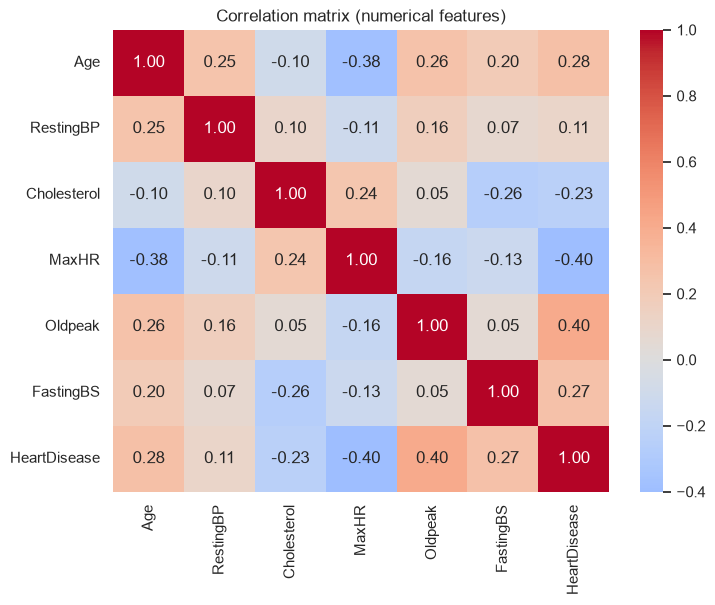

In [13]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[numerical_cols + binary_cols + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (numerical features)")
plt.show()

In [14]:
pb = {col: pointbiserialr(df[col], df[TARGET]) for col in numerical_cols + binary_cols}
pd.DataFrame({"r": {k: v[0] for k, v in pb.items()}, "p_value": {k: v[1] for k, v in pb.items()}}) \
  .sort_values("r", key=abs, ascending=False)

,r,p_value
Oldpeak,0.404,2.391e-37
MaxHR,-0.400,1.138e-36
Age,0.282,3.008e-18
FastingBS,0.267,1.754e-16
Cholesterol,-0.233,9.308e-13
RestingBP,0.108,1.095e-03


### 6.2 Categorical features (Cramér's V with the target)

In [15]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2, p, _, _ = chi2_contingency(table)
    n = table.values.sum()
    r, k = table.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1))), p

cv_scores = {col: cramers_v(df[col], df[TARGET]) for col in categorical_cols}
pd.DataFrame(cv_scores, index=["cramers_v", "p_value"]).T.sort_values("cramers_v", ascending=False)

,cramers_v,p_value
ST_Slope,0.623,5.168e-78
ChestPainType,0.540,8.084e-58
ExerciseAngina,0.492,2.908e-50
Sex,0.303,4.598e-20
RestingECG,0.109,4.229e-03


- Strongest numerical signals: `Oldpeak` (+), `MaxHR` (−), `Age` (+).
- `Cholesterol` shows a *negative* correlation with the target – this is an artefact of the 0-encoded missing values (see outliers below).
- Strongest categorical signals: `ST_Slope`, `ChestPainType`, `ExerciseAngina`.
- No pair of predictors is strongly collinear (|r| < 0.4), so all features can be kept.

## 7. Outlier analysis

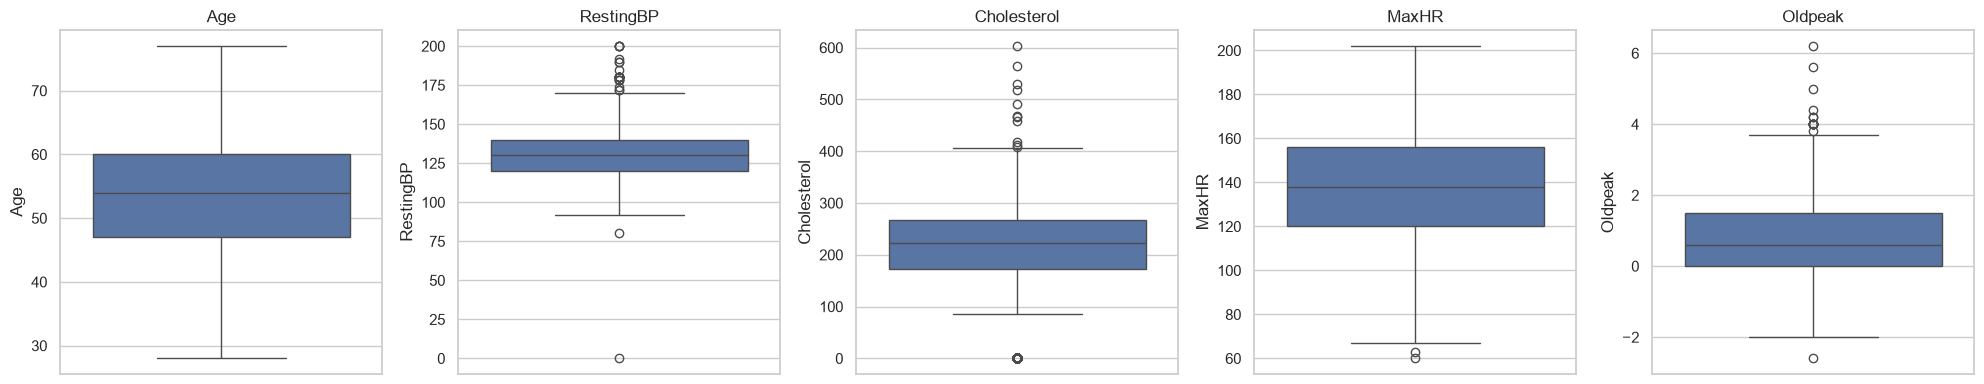

In [16]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, numerical_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [17]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

outliers = pd.DataFrame({
    "iqr_outliers": {c: iqr_outliers(df[c]) for c in numerical_cols},
    "zeros": {c: (df[c] == 0).sum() for c in numerical_cols},
})
outliers["iqr_outliers_%"] = (outliers["iqr_outliers"] / len(df) * 100).round(2)
outliers

,iqr_outliers,zeros,iqr_outliers_%
Age,0,0,0.00
RestingBP,28,1,3.05
Cholesterol,183,172,19.93
MaxHR,2,0,0.22
Oldpeak,16,368,1.74


In [18]:
chol_zero = df["Cholesterol"] == 0
print(f"Cholesterol == 0 : {chol_zero.sum()} rows ({chol_zero.mean():.1%})")
print(f"Disease rate when Cholesterol == 0 : {df.loc[chol_zero, TARGET].mean():.1%}")
print(f"Disease rate when Cholesterol  > 0 : {df.loc[~chol_zero, TARGET].mean():.1%}")
print(f"RestingBP == 0 : {(df['RestingBP'] == 0).sum()} row(s)")

Cholesterol == 0 : 172 rows (18.7%)
Disease rate when Cholesterol == 0 : 88.4%
Disease rate when Cholesterol  > 0 : 47.7%
RestingBP == 0 : 1 row(s)


**Outlier handling decisions**
- `Cholesterol == 0` (172 rows, ~19%) and `RestingBP == 0` (1 row) are **missing values**, not real measurements → convert to `NaN` and impute with the median *inside the pipeline* (so no information leaks from the test set).
- Because 0-cholesterol rows have a very high disease rate, a `Chol_missing` indicator flag is kept as a feature.
- Other outliers (e.g. very high cholesterol, `Oldpeak` up to 6.2) are clinically plausible, so they are kept; `StandardScaler` handles the scale.

## 8. Key features (mutual information)

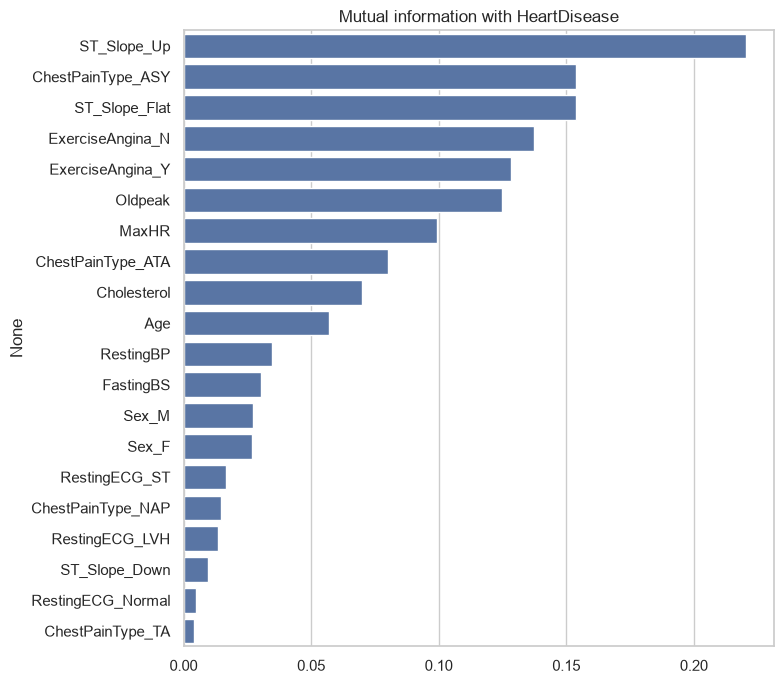

ST_Slope_Up          0.220
ChestPainType_ASY    0.154
ST_Slope_Flat        0.154
ExerciseAngina_N     0.137
ExerciseAngina_Y     0.128
Oldpeak              0.125
MaxHR                0.100
ChestPainType_ATA    0.080
Cholesterol          0.070
Age                  0.057
dtype: float64

In [19]:
X_mi = pd.get_dummies(df.drop(columns=TARGET), drop_first=False)
mi = pd.Series(mutual_info_classif(X_mi, df[TARGET], random_state=RANDOM_STATE), index=X_mi.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 7))
sns.barplot(x=mi.values, y=mi.index)
plt.title("Mutual information with HeartDisease")
plt.tight_layout()
plt.show()
mi.head(10)

**Key features:** `ST_Slope`, `ChestPainType`, `ExerciseAngina`, `Oldpeak`, `MaxHR`, followed by `Sex`, `Age` and `FastingBS`.

## 9. Train / test split

In [20]:
X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train target ratio:", y_train.mean().round(3), " Test target ratio:", y_test.mean().round(3))

Train: (734, 11)  Test: (184, 11)
Train target ratio: 0.553  Test target ratio: 0.554


## 10. Feature engineering

A custom transformer so the same steps are applied identically during cross-validation, on the test set and at prediction time:

| New / changed feature | Description |
|---|---|
| `Cholesterol`, `RestingBP` | 0 → `NaN` (imputed later) |
| `Chol_missing` | 1 if cholesterol was not recorded |
| `HR_reserve` | `MaxHR / (220 − Age)` – fraction of age-predicted max heart rate reached |
| `Oldpeak_pos` | 1 if there is any ST depression (`Oldpeak > 0`) |

In [21]:
class FeatureEngineer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X["Cholesterol"] = X["Cholesterol"].replace(0, np.nan)
        X["RestingBP"] = X["RestingBP"].replace(0, np.nan)
        X["Chol_missing"] = X["Cholesterol"].isna().astype(int)
        X["HR_reserve"] = X["MaxHR"] / (220 - X["Age"])
        X["Oldpeak_pos"] = (X["Oldpeak"] > 0).astype(int)
        return X

FeatureEngineer().fit_transform(X_train).head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,Chol_missing,HR_reserve,Oldpeak_pos
485,63,M,ATA,139,217.0,1,ST,128,Y,1.2,Flat,0,0.815,1
486,55,M,ATA,110,214.0,1,ST,180,N,0.4,Up,0,1.091,1
117,59,F,ASY,130,338.0,1,ST,130,Y,1.5,Flat,0,0.807,1
361,47,M,ASY,160,NaN,0,Normal,124,Y,0.0,Flat,1,0.717,0
296,50,M,ASY,145,NaN,1,Normal,139,Y,0.7,Flat,1,0.818,1


## 11. Preprocessing

In [22]:
num_features = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak", "HR_reserve"]
bin_features = ["FastingBS", "Chol_missing", "Oldpeak_pos"]
cat_features = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_features),
    ("bin", "passthrough", bin_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

def make_pipeline(model):
    return Pipeline([
        ("features", FeatureEngineer()),
        ("preprocess", preprocessor),
        ("select", SelectKBest(score_func=f_classif)),
        ("model", model),
    ])

make_pipeline(LogisticRegression())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('preprocess', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defaul

## 12. Model training with GridSearchCV

Every model uses the **same end-to-end pipeline**; `GridSearchCV` tunes both the number of selected features (`select__k`) and the model hyperparameters with 5-fold stratified cross-validation, optimising ROC-AUC. Only the training set is used here.

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
k_grid = [8, 10, 12, 15, "all"]

models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=5000, solver="liblinear"),
        {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10], "model__penalty": ["l1", "l2"]},
    ),
    "KNN": (
        KNeighborsClassifier(),
        {"model__n_neighbors": list(range(5, 41, 2)), "model__weights": ["uniform", "distance"], "model__p": [1, 2]},
    ),
    "SVM": (
        SVC(probability=True, random_state=RANDOM_STATE),
        {"model__kernel": ["rbf", "linear"], "model__C": [0.1, 0.3, 1, 3, 10], "model__gamma": ["scale", 0.003, 0.01, 0.03, 0.1]},
    ),
}

searches = {}
for name, (model, grid) in models.items():
    search = GridSearchCV(
        make_pipeline(model),
        param_grid={**grid, "select__k": k_grid},
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    searches[name] = search
    print(f"{name:20s} CV ROC-AUC = {search.best_score_:.4f}   best params = {search.best_params_}")

Logistic Regression  CV ROC-AUC = 0.9323   best params = {'model__C': 10, 'model__penalty': 'l2', 'select__k': 15}


KNN                  CV ROC-AUC = 0.9312   best params = {'model__n_neighbors': 17, 'model__p': 1, 'model__weights': 'uniform', 'select__k': 15}


SVM                  CV ROC-AUC = 0.9340   best params = {'model__C': 3, 'model__gamma': 0.03, 'model__kernel': 'rbf', 'select__k': 15}


## 13. Evaluation on the held-out test set

In [24]:
rows = []
probas = {}
for name, search in searches.items():
    proba = search.predict_proba(X_test)[:, 1]
    pred = search.predict(X_test)
    probas[name] = proba
    rows.append({
        "Model": name,
        "CV ROC-AUC": search.best_score_,
        "Test ROC-AUC": roc_auc_score(y_test, proba),
        "Test PR-AUC": average_precision_score(y_test, proba),
        "Accuracy": accuracy_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

results = pd.DataFrame(rows).set_index("Model").sort_values("Test ROC-AUC", ascending=False)
results.style.format("{:.4f}").highlight_max(color="lightgreen")

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Accuracy,F1
Model,,,,,
SVM,0.9340,0.9427,0.9511,0.8859,0.8995
Logistic Regression,0.9323,0.9393,0.9453,0.9022,0.9126
KNN,0.9312,0.9353,0.9234,0.9022,0.9118


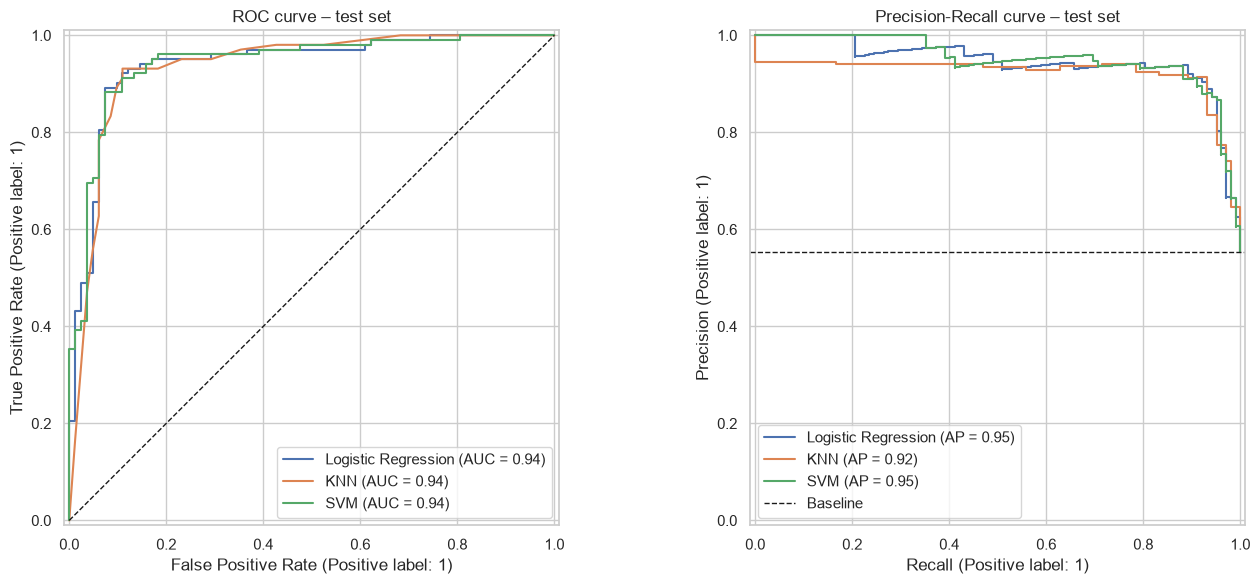

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for name, proba in probas.items():
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, proba, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("ROC curve – test set")
axes[1].axhline(y_test.mean(), ls="--", c="k", lw=1, label="Baseline")
axes[1].set_title("Precision-Recall curve – test set")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.savefig("images/roc_pr_curves.png", dpi=120, bbox_inches="tight")
plt.show()

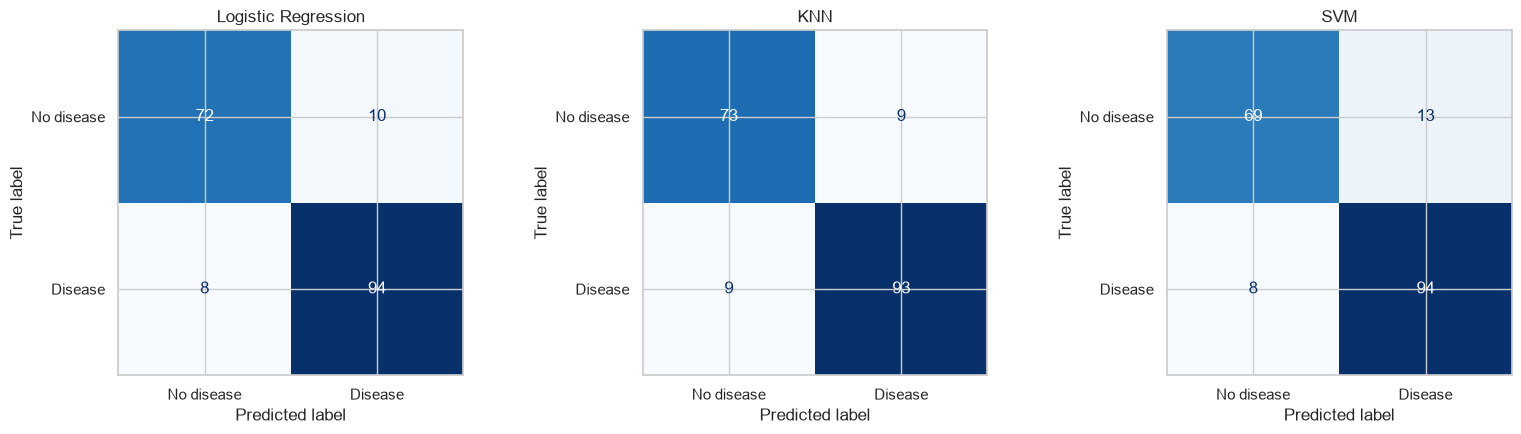

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, search) in zip(axes, searches.items()):
    cm = confusion_matrix(y_test, search.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["No disease", "Disease"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.savefig("images/confusion_matrices.png", dpi=120, bbox_inches="tight")
plt.show()

## 14. Best model

In [27]:
best_name = results["Test ROC-AUC"].idxmax()
best = searches[best_name].best_estimator_

print(f"Best model: {best_name}")
print(f"ROC-AUC : {results.loc[best_name, 'Test ROC-AUC']:.2%}")
print(f"PR-AUC  : {results.loc[best_name, 'Test PR-AUC']:.2%}\n")
print(classification_report(y_test, best.predict(X_test), target_names=["No disease", "Disease"]))

Best model: SVM
ROC-AUC : 94.27%
PR-AUC  : 95.11%

              precision    recall  f1-score   support

  No disease       0.90      0.84      0.87        82
     Disease       0.88      0.92      0.90       102

    accuracy                           0.89       184
   macro avg       0.89      0.88      0.88       184
weighted avg       0.89      0.89      0.89       184



### 14.1 Features kept by `SelectKBest`

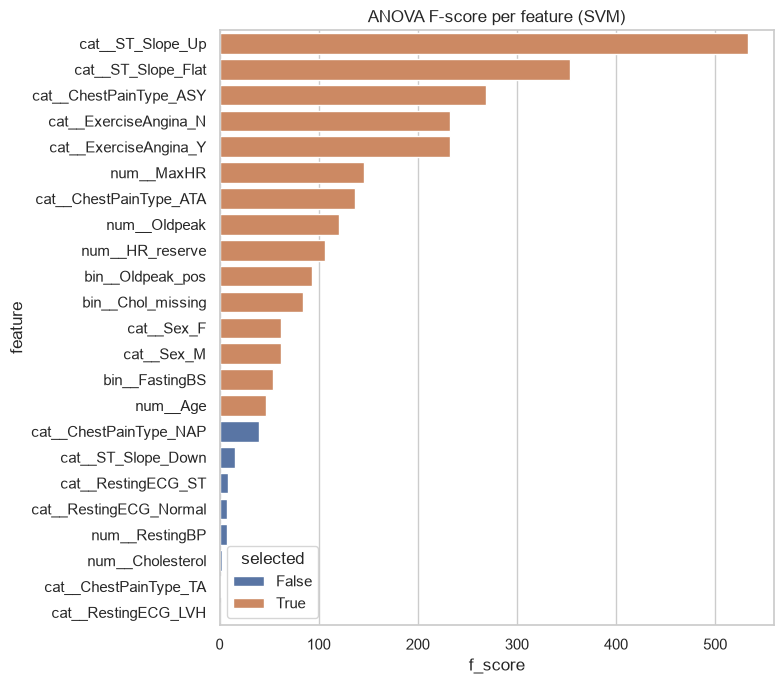

,feature,f_score,selected
22,cat__ST_Slope_Up,532.727,True
21,cat__ST_Slope_Flat,353.734,True
11,cat__ChestPainType_ASY,268.663,True
18,cat__ExerciseAngina_N,232.371,True
19,cat__ExerciseAngina_Y,232.371,True
3,num__MaxHR,145.523,True
12,cat__ChestPainType_ATA,136.599,True
4,num__Oldpeak,120.978,True
5,num__HR_reserve,106.664,True
8,bin__Oldpeak_pos,93.428,True


In [28]:
feature_names = best.named_steps["preprocess"].get_feature_names_out()
selector = best.named_steps["select"]
scores = pd.DataFrame({
    "feature": feature_names,
    "f_score": selector.scores_,
    "selected": selector.get_support(),
}).sort_values("f_score", ascending=False)

plt.figure(figsize=(8, 7))
sns.barplot(data=scores, x="f_score", y="feature", hue="selected", dodge=False)
plt.title(f"ANOVA F-score per feature ({best_name})")
plt.tight_layout()
plt.show()
scores

### 14.2 Predicting on a new patient

In [29]:
new_patient = pd.DataFrame([{
    "Age": 58, "Sex": "M", "ChestPainType": "ASY", "RestingBP": 140, "Cholesterol": 0,
    "FastingBS": 1, "RestingECG": "Normal", "MaxHR": 110, "ExerciseAngina": "Y",
    "Oldpeak": 2.0, "ST_Slope": "Flat",
}])
print(f"Probability of heart disease: {best.predict_proba(new_patient)[0, 1]:.1%}")

Probability of heart disease: 99.3%


## 15. Conclusions

- **EDA** showed that `ST_Slope`, `ChestPainType`, `ExerciseAngina`, `Oldpeak` and `MaxHR` are the strongest predictors, and that `Cholesterol = 0` / `RestingBP = 0` are hidden missing values rather than real measurements.
- Fixing those values, adding engineered features (`Chol_missing`, `HR_reserve`, `Oldpeak_pos`) and tuning everything inside a single **leak-free pipeline** with `GridSearchCV` improved the baseline Logistic Regression (≈91.9% ROC-AUC) noticeably.
- The final comparison table above shows the tuned **Logistic Regression, KNN and SVM**; the best model's test ROC-AUC and PR-AUC are printed in section 14.
- Since the dataset is small (918 rows), the cross-validated ROC-AUC is reported alongside the test score as a more stable estimate.